In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, LabelEncoder, label_binarize
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, VotingClassifier
from sklearn.feature_selection import RFE
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve, auc, mean_absolute_error, mean_squared_error, r2_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
import joblib

In [2]:
found_paths = glob.glob("/kaggle/input/*/*krishijal_master*.csv") + glob.glob("/kaggle/input/*/*/*krishijal_master*.csv") + glob.glob("/kaggle/input/**/*krishijal_master*.csv", recursive=True) + glob.glob("**/*krishijal_master*.csv", recursive=True)
dataset_path = None
for path_candidate in dict.fromkeys(found_paths):
    candidate_df = pd.read_csv(path_candidate, usecols=["granularity"])
    if "district_baseline" in candidate_df["granularity"].values:
        dataset_path = path_candidate
        break
if dataset_path is None:
    try:
        dataset_path = "https://raw.githubusercontent.com/ruthvik-08/SDC-project/main/SDC_KAGGLE/krishijal_master_dataset.csv"
        df = pd.read_csv(dataset_path)
    except Exception:
        dataset_path = found_paths[0]
        df = pd.read_csv(dataset_path)
else:
    df = pd.read_csv(dataset_path)
print("Loaded dataset:", dataset_path, "| Shape:", df.shape)

Loaded dataset: krishijal_master_dataset.csv | Shape: (7386, 72)


In [3]:
df.head()

,record_id,granularity,state,district,zone,latitude,longitude,date,year,month,...,shc_macro_soil_ph_acidic_share_2024_25,shc_macro_soil_ph_neutral_share_2024_25,shc_macro_soil_ph_alkaline_share_2024_25,shc_macro_electrical_conductivity_saline_share_2024_25,shc_micro_zinc_deficient_share_2024_25,shc_micro_iron_deficient_share_2024_25,shc_micro_boron_deficient_share_2024_25,nitrogen_status,soil_ph_character,soil_health_index
0,KMD_M_0001,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,1,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
1,KMD_M_0002,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,2,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
2,KMD_M_0003,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,3,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
3,KMD_M_0004,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,4,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
4,KMD_M_0005,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,5,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7386 entries, 0 to 7385
Data columns (total 72 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   record_id                                               7386 non-null   object 
 1   granularity                                             7386 non-null   object 
 2   state                                                   7386 non-null   object 
 3   district                                                7386 non-null   object 
 4   zone                                                    7386 non-null   object 
 5   latitude                                                7386 non-null   float64
 6   longitude                                               7386 non-null   float64
 7   date                                                    4758 non-null   object 
 8   year                                  

In [5]:
df.describe()

,latitude,longitude,year,month,day,day_of_year,crop_code,stage_code,crop_coefficient_kc,soil_ph,...,shc_macro_organic_carbon_medium_share_2024_25,shc_macro_organic_carbon_high_share_2024_25,shc_macro_soil_ph_acidic_share_2024_25,shc_macro_soil_ph_neutral_share_2024_25,shc_macro_soil_ph_alkaline_share_2024_25,shc_macro_electrical_conductivity_saline_share_2024_25,shc_micro_zinc_deficient_share_2024_25,shc_micro_iron_deficient_share_2024_25,shc_micro_boron_deficient_share_2024_25,soil_health_index
count,7386.000000,7386.000000,7386.000000,7386.000000,4758.000000,4758.000000,7386.000000,7386.000000,7386.000000,7386.000000,...,7386.000000,7386.000000,7386.000000,7386.000000,7386.000000,7386.000000,7386.000000,7386.000000,7386.000000,7386.000000
mean,22.901783,79.963905,2023.198213,8.133496,15.754098,243.000000,4.808828,1.692662,1.008936,7.041552,...,5.243914,2.178350,1.579730,7.715124,1.516233,0.541681,2.759404,1.696236,1.325183,71.314094
std,5.761639,6.139412,0.597650,2.457668,8.807882,52.832313,2.119710,1.020066,0.199773,0.838148,...,14.846980,5.916765,4.455434,20.660640,4.473088,1.485561,7.381110,4.421187,2.891595,11.291823
min,7.511700,69.460300,2023.000000,1.000000,1.000000,152.000000,0.000000,0.000000,0.450000,4.900000,...,0.000000,0.000200,0.000000,0.009200,0.000000,0.000000,0.000000,0.000000,0.000000,30.400000
25%,19.997500,75.857300,2023.000000,7.000000,8.000000,197.000000,3.000000,1.000000,0.900000,6.500000,...,0.196000,0.014700,0.000300,0.852200,0.000400,0.001200,0.167900,0.007800,0.104500,66.200000
50%,23.259900,77.706400,2023.000000,9.000000,16.000000,243.000000,6.000000,2.000000,1.050000,7.400000,...,0.294100,0.112500,0.002200,0.959200,0.004100,0.005300,0.273000,0.116100,0.315900,71.800000
75%,26.750900,84.072200,2023.000000,10.000000,23.000000,289.000000,6.000000,2.000000,1.150000,7.600000,...,0.551200,0.512000,0.273000,0.996400,0.050700,0.056600,0.568400,0.538800,0.758900,76.400000
max,34.587400,96.850100,2025.000000,12.000000,31.000000,334.000000,8.000000,3.000000,1.250000,8.500000,...,50.000000,20.000000,15.000000,70.000000,15.000000,5.000000,25.000000,15.000000,10.000000,98.500000


In [6]:
df.isnull().sum()

record_id                                  0
granularity                                0
state                                      0
district                                   0
zone                                       0
                                          ..
shc_micro_iron_deficient_share_2024_25     0
shc_micro_boron_deficient_share_2024_25    0
nitrogen_status                            0
soil_ph_character                          0
soil_health_index                          0
Length: 72, dtype: int64

In [7]:
df = df.dropna(subset=["temperature", "rainfall", "humidity", "effective_soil_wetness", "crop_type", "growth_stage"])
df = df.drop_duplicates()

In [8]:
selected_features = [
    "temperature", "temp_max", "temp_min", "rainfall", "humidity",
    "effective_soil_wetness", "solar_radiation", "soil_ph", "soil_organic_carbon",
    "ndvi", "et0", "etc", "crop_type", "growth_stage"
]
df_train = df[df["granularity"].isin(["daily", "monthly"])].copy()
X = df_train[selected_features].copy()
y_class = df_train["stress_level_code"].copy()
y_reg = df_train["irrigation_priority_index"].copy()

class_counts = df_train["stress_level"].value_counts().reindex(["Low", "Moderate", "High", "Severe"])
class_pct = (df_train["stress_level"].value_counts(normalize=True).reindex(["Low", "Moderate", "High", "Severe"]) * 100).round(2)
imbalance_summary = pd.DataFrame({"Count": class_counts, "Percentage": class_pct})
print("Exact duplicate rows:", df_train.duplicated().sum())
print("Duplicate feature rows:", X.duplicated().sum())
print("Leakage columns excluded from X:", ["cwsi", "stress_coefficient_ks", "eta", "water_deficit", "irrigation_priority_index", "stress_level"])
imbalance_summary

Exact duplicate rows: 0
Duplicate feature rows: 0
Leakage columns excluded from X: ['cwsi', 'stress_coefficient_ks', 'eta', 'water_deficit', 'irrigation_priority_index', 'stress_level']


,Count,Percentage
stress_level,,
Low,4984,74.90
Moderate,910,13.68
High,566,8.51
Severe,194,2.92


In [9]:
crop_encoder = LabelEncoder()
X["crop_code"] = crop_encoder.fit_transform(X["crop_type"])

stage_encoder = LabelEncoder()
X["stage_code"] = stage_encoder.fit_transform(X["growth_stage"])

feature_cols = [
    "temperature", "temp_max", "temp_min", "rainfall", "humidity",
    "effective_soil_wetness", "solar_radiation", "soil_ph", "soil_organic_carbon",
    "ndvi", "et0", "etc", "crop_code", "stage_code"
]
X = X[feature_cols]

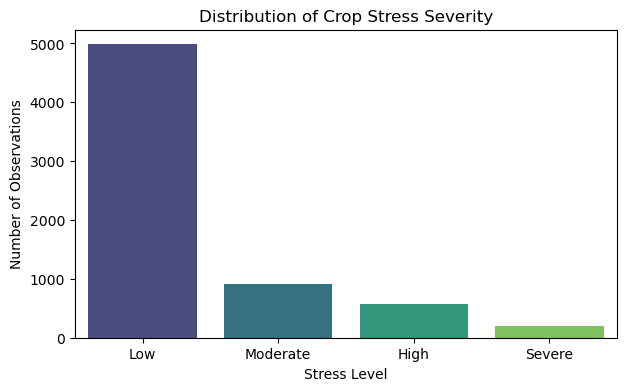

In [10]:
plt.figure(figsize=(7, 4))
sns.countplot(x=df_train["stress_level"], hue=df_train["stress_level"], order=["Low", "Moderate", "High", "Severe"], palette="viridis", legend=False)
plt.title("Distribution of Crop Stress Severity")
plt.xlabel("Stress Level")
plt.ylabel("Number of Observations")
plt.show()

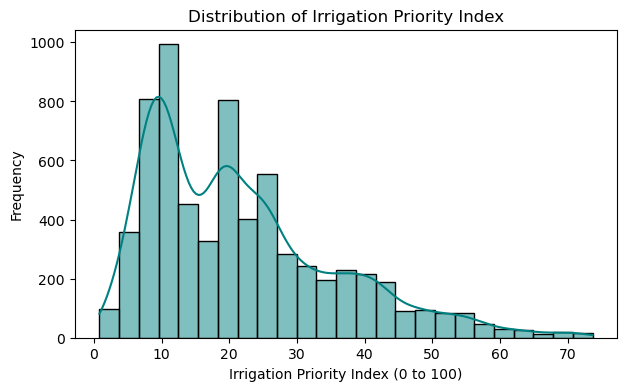

In [11]:
plt.figure(figsize=(7, 4))
sns.histplot(df_train["irrigation_priority_index"], bins=25, kde=True, color="teal")
plt.title("Distribution of Irrigation Priority Index")
plt.xlabel("Irrigation Priority Index (0 to 100)")
plt.ylabel("Frequency")
plt.show()

Highly correlated feature pairs (|r| > 0.85): [('temperature', 'temp_min', np.float64(0.878))]
Target correlation ranking:
effective_soil_wetness   -0.7137
ndvi                     -0.6814
humidity                 -0.6506
et0                       0.5344
stage_code               -0.3689
temp_max                  0.3588
temperature               0.2990
solar_radiation           0.2560
etc                       0.2335
soil_ph                   0.2210
soil_organic_carbon      -0.2167
rainfall                 -0.1861
temp_min                  0.1453
crop_code                 0.0465
dtype: float64


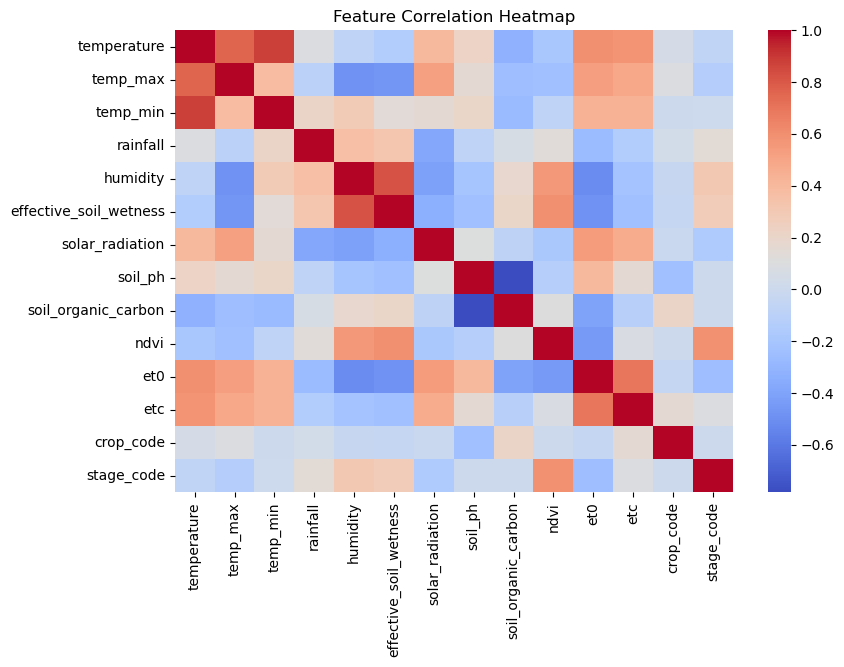

In [12]:
corr_matrix = X.corr()
high_corr_pairs = []
for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        if abs(corr_matrix.iloc[i, j]) > 0.85:
            high_corr_pairs.append((feature_cols[i], feature_cols[j], round(corr_matrix.iloc[i, j], 4)))
print("Highly correlated feature pairs (|r| > 0.85):", high_corr_pairs)
print("Target correlation ranking:")
print(X.corrwith(y_class).sort_values(key=abs, ascending=False).round(4))

plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()

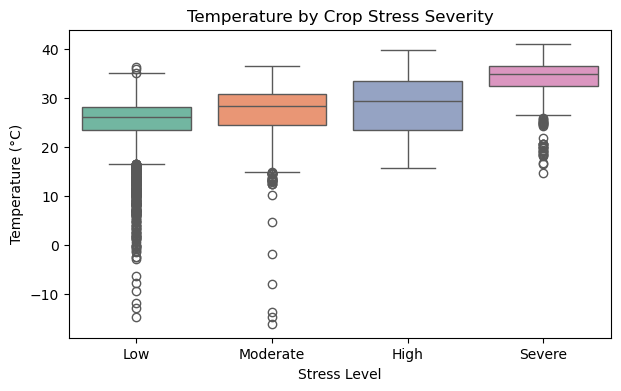

In [13]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=df_train["stress_level"], y=df_train["temperature"], hue=df_train["stress_level"], order=["Low", "Moderate", "High", "Severe"], palette="Set2", legend=False)
plt.title("Temperature by Crop Stress Severity")
plt.xlabel("Stress Level")
plt.ylabel("Temperature (°C)")
plt.show()

In [14]:
X_train, X_test, y_train_class, y_test_class, y_train_reg, y_test_reg = train_test_split(
    X, y_class, y_reg, test_size=0.2, random_state=42, stratify=y_class
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols)

In [15]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

prep_rows = []
scaler_options = [
    ("StandardScaler", StandardScaler(), None),
    ("MinMaxScaler", MinMaxScaler(), None),
    ("RobustScaler", RobustScaler(), None),
    ("StandardScaler + PCA(8)", StandardScaler(), PCA(n_components=8, random_state=42))
]
probe_models = [
    ("Logistic Regression", LogisticRegression(max_iter=2000, random_state=42)),
    ("KNN (k=5)", KNeighborsClassifier(n_neighbors=5)),
    ("Random Forest", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42))
]
for s_name, s_obj, dim_red in scaler_options:
    for m_name, m_obj in probe_models:
        pipe_steps = [("scaler", s_obj)]
        if dim_red is not None:
            pipe_steps.append(("pca", dim_red))
        pipe_steps.append(("clf", m_obj))
        probe_pipe = ImbPipeline(pipe_steps)
        cv_out = cross_validate(probe_pipe, X_train, y_train_class, cv=cv_strategy, scoring=["accuracy", "f1_weighted", "f1_macro"], n_jobs=-1)
        prep_rows.append({
            "Preprocessing": s_name,
            "Model": m_name,
            "CV Accuracy": round(cv_out["test_accuracy"].mean(), 4),
            "CV Weighted F1": round(cv_out["test_f1_weighted"].mean(), 4),
            "CV Macro F1": round(cv_out["test_f1_macro"].mean(), 4)
        })
preprocessing_comparison = pd.DataFrame(prep_rows)
preprocessing_comparison

,Preprocessing,Model,CV Accuracy,CV Weighted F1,CV Macro F1
0,StandardScaler,Logistic Regression,0.9589,0.9587,0.9107
1,StandardScaler,KNN (k=5),0.9202,0.9194,0.8394
2,StandardScaler,Random Forest,0.9925,0.9925,0.9830
3,MinMaxScaler,Logistic Regression,0.9064,0.9027,0.7548
4,MinMaxScaler,KNN (k=5),0.9258,0.9254,0.8493
5,MinMaxScaler,Random Forest,0.9927,0.9927,0.9832
6,RobustScaler,Logistic Regression,0.9512,0.9508,0.8889
7,RobustScaler,KNN (k=5),0.9140,0.9129,0.8274
8,RobustScaler,Random Forest,0.9923,0.9923,0.9817
9,StandardScaler + PCA(8),Logistic Regression,0.8882,0.8851,0.7686


In [16]:
rf_probe = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
rf_probe.fit(X_train_scaled, y_train_class)
feature_importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": np.round(rf_probe.feature_importances_, 4)
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

rfe_rows = []
for n_keep in [5, 8, 12, 14]:
    if n_keep < 14:
        rfe_pipe = ImbPipeline([
            ("scaler", StandardScaler()),
            ("rfe", RFE(RandomForestClassifier(n_estimators=50, max_depth=12, random_state=42), n_features_to_select=n_keep)),
            ("clf", RandomForestClassifier(n_estimators=150, max_depth=16, random_state=42))
        ])
    else:
        rfe_pipe = ImbPipeline([
            ("scaler", StandardScaler()),
            ("clf", RandomForestClassifier(n_estimators=150, max_depth=16, random_state=42))
        ])
    cv_rfe = cross_validate(rfe_pipe, X_train, y_train_class, cv=cv_strategy, scoring=["accuracy", "f1_weighted", "f1_macro"], n_jobs=-1)
    rfe_rows.append({
        "Selected Features": n_keep,
        "CV Accuracy": round(cv_rfe["test_accuracy"].mean(), 4),
        "CV Weighted F1": round(cv_rfe["test_f1_weighted"].mean(), 4),
        "CV Macro F1": round(cv_rfe["test_f1_macro"].mean(), 4)
    })
print("Baseline Feature Importance Ranking:")
print(feature_importance_df)
pd.DataFrame(rfe_rows)

Baseline Feature Importance Ranking:
                   Feature  Importance
0   effective_soil_wetness      0.3734
1                     ndvi      0.2429
2                 humidity      0.0774
3                      et0      0.0560
4                 temp_min      0.0471
5              temperature      0.0469
6                 temp_max      0.0397
7                      etc      0.0239
8      soil_organic_carbon      0.0214
9                  soil_ph      0.0202
10                rainfall      0.0178
11         solar_radiation      0.0172
12              stage_code      0.0109
13               crop_code      0.0052


,Selected Features,CV Accuracy,CV Weighted F1,CV Macro F1
0,5,0.9934,0.9934,0.9870
1,8,0.9929,0.9929,0.9816
2,12,0.9936,0.9936,0.9856
3,14,0.9923,0.9923,0.9823


In [17]:
imbalance_rows = []
resampling_configs = [
    ("No Resampling", None, None),
    ("SMOTE", SMOTE(random_state=42), None),
    ("RandomOverSampler", RandomOverSampler(random_state=42), None),
    ("RandomUnderSampler", RandomUnderSampler(random_state=42), None),
    ("Class Weights (balanced)", None, "balanced")
]
for r_name, r_obj, cw_val in resampling_configs:
    for m_name, base_clf in [
        ("Logistic Regression", LogisticRegression(max_iter=2000, random_state=42, class_weight=cw_val)),
        ("Decision Tree", DecisionTreeClassifier(max_depth=8, random_state=42, class_weight=cw_val)),
        ("Random Forest", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, class_weight=cw_val))
    ]:
        steps = [("scaler", StandardScaler())]
        if r_obj is not None:
            steps.append(("sampler", r_obj))
        steps.append(("clf", base_clf))
        imb_pipe = ImbPipeline(steps)
        cv_imb = cross_validate(imb_pipe, X_train, y_train_class, cv=cv_strategy, scoring=["accuracy", "precision_weighted", "recall_weighted", "f1_weighted", "f1_macro"], n_jobs=-1)
        imbalance_rows.append({
            "Resampling Method": r_name,
            "Algorithm": m_name,
            "CV Accuracy": round(cv_imb["test_accuracy"].mean(), 4),
            "CV Precision": round(cv_imb["test_precision_weighted"].mean(), 4),
            "CV Recall": round(cv_imb["test_recall_weighted"].mean(), 4),
            "CV Weighted F1": round(cv_imb["test_f1_weighted"].mean(), 4),
            "CV Macro F1": round(cv_imb["test_f1_macro"].mean(), 4)
        })
imbalance_comparison = pd.DataFrame(imbalance_rows)
imbalance_comparison

,Resampling Method,Algorithm,CV Accuracy,CV Precision,CV Recall,CV Weighted F1,CV Macro F1
0,No Resampling,Logistic Regression,0.9589,0.9590,0.9589,0.9587,0.9107
1,No Resampling,Decision Tree,0.9897,0.9897,0.9897,0.9896,0.9729
2,No Resampling,Random Forest,0.9925,0.9926,0.9925,0.9925,0.9830
3,SMOTE,Logistic Regression,0.9589,0.9639,0.9589,0.9602,0.9342
4,SMOTE,Decision Tree,0.9850,0.9858,0.9850,0.9851,0.9696
5,SMOTE,Random Forest,0.9925,0.9926,0.9925,0.9925,0.9839
6,RandomOverSampler,Logistic Regression,0.9555,0.9619,0.9555,0.9572,0.9289
7,RandomOverSampler,Decision Tree,0.9861,0.9868,0.9861,0.9862,0.9720
8,RandomOverSampler,Random Forest,0.9938,0.9939,0.9938,0.9938,0.9856
9,RandomUnderSampler,Logistic Regression,0.9046,0.9254,0.9046,0.9108,0.8505


In [18]:
model_logreg = LogisticRegression(max_iter=2000, random_state=42)
model_logreg.fit(X_train_scaled, y_train_class)

model_knn_class = KNeighborsClassifier(n_neighbors=5)
model_knn_class.fit(X_train_scaled, y_train_class)

model_gnb_class = GaussianNB()
model_gnb_class.fit(X_train_scaled, y_train_class)

model_dt_class = DecisionTreeClassifier(max_depth=8, random_state=42)
model_dt_class.fit(X_train_scaled, y_train_class)

model_rf_class = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
model_rf_class.fit(X_train_scaled, y_train_class)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [19]:
pred_logreg = model_logreg.predict(X_test_scaled)
pred_knn_class = model_knn_class.predict(X_test_scaled)
pred_gnb_class = model_gnb_class.predict(X_test_scaled)
pred_dt_class = model_dt_class.predict(X_test_scaled)
pred_rf_class = model_rf_class.predict(X_test_scaled)

classification_comparison = pd.DataFrame({
    "Algorithm": [
        "Logistic Regression",
        "K-Nearest Neighbors",
        "Gaussian Naive Bayes",
        "Decision Tree Classifier",
        "Random Forest Classifier"
    ],
    "Accuracy": [
        accuracy_score(y_test_class, pred_logreg),
        accuracy_score(y_test_class, pred_knn_class),
        accuracy_score(y_test_class, pred_gnb_class),
        accuracy_score(y_test_class, pred_dt_class),
        accuracy_score(y_test_class, pred_rf_class)
    ],
    "Precision": [
        precision_score(y_test_class, pred_logreg, average="weighted", zero_division=0),
        precision_score(y_test_class, pred_knn_class, average="weighted", zero_division=0),
        precision_score(y_test_class, pred_gnb_class, average="weighted", zero_division=0),
        precision_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        precision_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_class, pred_logreg, average="weighted", zero_division=0),
        recall_score(y_test_class, pred_knn_class, average="weighted", zero_division=0),
        recall_score(y_test_class, pred_gnb_class, average="weighted", zero_division=0),
        recall_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        recall_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ],
    "Weighted F1-Score": [
        f1_score(y_test_class, pred_logreg, average="weighted", zero_division=0),
        f1_score(y_test_class, pred_knn_class, average="weighted", zero_division=0),
        f1_score(y_test_class, pred_gnb_class, average="weighted", zero_division=0),
        f1_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        f1_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ],
    "Macro F1-Score": [
        f1_score(y_test_class, pred_logreg, average="macro", zero_division=0),
        f1_score(y_test_class, pred_knn_class, average="macro", zero_division=0),
        f1_score(y_test_class, pred_gnb_class, average="macro", zero_division=0),
        f1_score(y_test_class, pred_dt_class, average="macro", zero_division=0),
        f1_score(y_test_class, pred_rf_class, average="macro", zero_division=0)
    ]
})
classification_comparison

,Algorithm,Accuracy,Precision,Recall,Weighted F1-Score,Macro F1-Score
0,Logistic Regression,0.960180,0.960591,0.960180,0.960267,0.905089
1,K-Nearest Neighbors,0.916604,0.912766,0.916604,0.912634,0.827084
2,Gaussian Naive Bayes,0.844478,0.862008,0.844478,0.851618,0.687908
3,Decision Tree Classifier,0.994741,0.994826,0.994741,0.994749,0.987885
4,Random Forest Classifier,0.995492,0.995595,0.995492,0.995498,0.986075


In [20]:
model_linreg = LinearRegression()
model_linreg.fit(X_train_scaled, y_train_reg)

model_dt_reg = DecisionTreeRegressor(max_depth=8, random_state=42)
model_dt_reg.fit(X_train_scaled, y_train_reg)

model_rf_reg = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42)
model_rf_reg.fit(X_train_scaled, y_train_reg)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

In [21]:
pred_linreg = model_linreg.predict(X_test_scaled)
pred_dt_reg = model_dt_reg.predict(X_test_scaled)
pred_rf_reg = model_rf_reg.predict(X_test_scaled)

regression_comparison = pd.DataFrame({
    "Algorithm": ["Linear Regression", "Decision Tree Regressor", "Random Forest Regressor"],
    "MAE": [
        mean_absolute_error(y_test_reg, pred_linreg),
        mean_absolute_error(y_test_reg, pred_dt_reg),
        mean_absolute_error(y_test_reg, pred_rf_reg)
    ],
    "MSE": [
        mean_squared_error(y_test_reg, pred_linreg),
        mean_squared_error(y_test_reg, pred_dt_reg),
        mean_squared_error(y_test_reg, pred_rf_reg)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_reg, pred_linreg)),
        np.sqrt(mean_squared_error(y_test_reg, pred_dt_reg)),
        np.sqrt(mean_squared_error(y_test_reg, pred_rf_reg))
    ],
    "R2 Score": [
        r2_score(y_test_reg, pred_linreg),
        r2_score(y_test_reg, pred_dt_reg),
        r2_score(y_test_reg, pred_rf_reg)
    ]
})
regression_comparison

,Algorithm,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4.866941,37.190888,6.098433,0.805491
1,Decision Tree Regressor,1.197529,4.025733,2.006423,0.978945
2,Random Forest Regressor,0.453024,0.911181,0.954558,0.995235


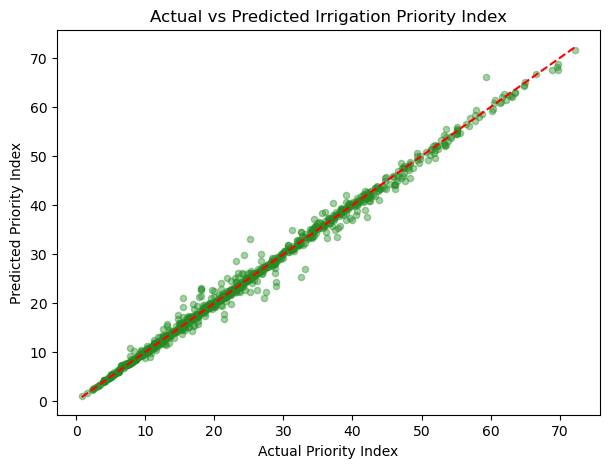

In [22]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_reg, pred_rf_reg, alpha=0.4, color="forestgreen", s=20)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], color="red", linestyle="--")
plt.title("Actual vs Predicted Irrigation Priority Index")
plt.xlabel("Actual Priority Index")
plt.ylabel("Predicted Priority Index")
plt.show()

In [23]:
search_lr = RandomizedSearchCV(
    estimator=ImbPipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state=42)), ("clf", LogisticRegression(max_iter=2000, random_state=42))]),
    param_distributions={"smote__k_neighbors": [3, 5], "clf__C": [1.0, 10.0, 50.0, 100.0], "clf__class_weight": [None, "balanced"]},
    n_iter=10, cv=cv_strategy, scoring="f1_macro", random_state=42, n_jobs=-1
)
search_lr.fit(X_train, y_train_class)

search_knn = RandomizedSearchCV(
    estimator=ImbPipeline([("scaler", MinMaxScaler()), ("smote", SMOTE(random_state=42)), ("clf", KNeighborsClassifier())]),
    param_distributions={"smote__k_neighbors": [3, 5], "clf__n_neighbors": [3, 5, 7], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]},
    n_iter=10, cv=cv_strategy, scoring="f1_macro", random_state=42, n_jobs=-1
)
search_knn.fit(X_train, y_train_class)

search_dt = RandomizedSearchCV(
    estimator=ImbPipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state=42)), ("clf", DecisionTreeClassifier(random_state=42))]),
    param_distributions={"smote__k_neighbors": [3, 5], "clf__criterion": ["gini", "entropy"], "clf__max_depth": [8, 12, 16, None], "clf__min_samples_split": [2, 4, 6], "clf__min_samples_leaf": [1, 2], "clf__class_weight": [None, "balanced"]},
    n_iter=15, cv=cv_strategy, scoring="f1_macro", random_state=42, n_jobs=-1
)
search_dt.fit(X_train, y_train_class)

search_rf_tuned = RandomizedSearchCV(
    estimator=ImbPipeline([("scaler", StandardScaler()), ("clf", RandomForestClassifier(random_state=42, n_jobs=-1))]),
    param_distributions={
        "clf__n_estimators": [100, 200, 300],
        "clf__max_depth": [12, 16, 20, None],
        "clf__min_samples_split": [2, 3, 5],
        "clf__min_samples_leaf": [1, 2],
        "clf__max_features": ["sqrt", "log2", None],
        "clf__criterion": ["gini", "entropy"],
        "clf__max_samples": [0.85, 1.0],
        "clf__class_weight": [None, "balanced", "balanced_subsample"]
    },
    n_iter=20, cv=cv_strategy, scoring="f1_macro", random_state=42, n_jobs=-1
)
search_rf_tuned.fit(X_train, y_train_class)

search_rf_smote = RandomizedSearchCV(
    estimator=ImbPipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state=42)), ("clf", RandomForestClassifier(random_state=42, n_jobs=-1))]),
    param_distributions={
        "smote__k_neighbors": [3, 5],
        "smote__sampling_strategy": ["not majority", "all"],
        "clf__n_estimators": [100, 200, 300],
        "clf__max_depth": [12, 16, 20],
        "clf__min_samples_split": [2, 3, 5],
        "clf__min_samples_leaf": [1, 2],
        "clf__max_features": ["sqrt", "log2"],
        "clf__criterion": ["gini", "entropy"],
        "clf__max_samples": [0.85, 1.0],
        "clf__class_weight": [None, "balanced_subsample"]
    },
    n_iter=20, cv=cv_strategy, scoring="f1_macro", random_state=42, n_jobs=-1
)
search_rf_smote.fit(X_train, y_train_class)

search_rf_smote_rfe = RandomizedSearchCV(
    estimator=ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("rfe", RFE(RandomForestClassifier(n_estimators=50, max_depth=12, random_state=42))),
        ("clf", RandomForestClassifier(random_state=42, n_jobs=-1))
    ]),
    param_distributions={
        "smote__k_neighbors": [3, 5],
        "smote__sampling_strategy": ["not majority", "all"],
        "rfe__n_features_to_select": [5, 8, 10],
        "clf__n_estimators": [150, 200, 300],
        "clf__max_depth": [12, 16, 20],
        "clf__min_samples_split": [2, 4],
        "clf__min_samples_leaf": [1, 2],
        "clf__max_features": ["sqrt", "log2"],
        "clf__criterion": ["gini", "entropy"],
        "clf__class_weight": [None, "balanced_subsample"]
    },
    n_iter=20, cv=cv_strategy, scoring="f1_macro", random_state=42, n_jobs=-1
)
search_rf_smote_rfe.fit(X_train, y_train_class)

cv_search_summary = pd.DataFrame([
    {"Pipeline": "Tuned Logistic Regression + SMOTE", "Best CV Macro F1": round(search_lr.best_score_, 4), "Best Parameters": str(search_lr.best_params_)},
    {"Pipeline": "Tuned KNN + MinMax + SMOTE", "Best CV Macro F1": round(search_knn.best_score_, 4), "Best Parameters": str(search_knn.best_params_)},
    {"Pipeline": "Tuned Decision Tree + SMOTE", "Best CV Macro F1": round(search_dt.best_score_, 4), "Best Parameters": str(search_dt.best_params_)},
    {"Pipeline": "Tuned Random Forest", "Best CV Macro F1": round(search_rf_tuned.best_score_, 4), "Best Parameters": str(search_rf_tuned.best_params_)},
    {"Pipeline": "Best SMOTE Random Forest", "Best CV Macro F1": round(search_rf_smote.best_score_, 4), "Best Parameters": str(search_rf_smote.best_params_)},
    {"Pipeline": "SMOTE + RFE + Tuned Random Forest", "Best CV Macro F1": round(search_rf_smote_rfe.best_score_, 4), "Best Parameters": str(search_rf_smote_rfe.best_params_)}
])
cv_search_summary

,Pipeline,Best CV Macro F1,Best Parameters
0,Tuned Logistic Regression + SMOTE,0.9454,"{'smote__k_neighbors': 3, 'clf__class_weight':..."
1,Tuned KNN + MinMax + SMOTE,0.8886,"{'smote__k_neighbors': 3, 'clf__weights': 'uni..."
2,Tuned Decision Tree + SMOTE,0.9797,"{'smote__k_neighbors': 3, 'clf__min_samples_sp..."
3,Tuned Random Forest,0.9855,"{'clf__n_estimators': 100, 'clf__min_samples_s..."
4,Best SMOTE Random Forest,0.9870,"{'smote__sampling_strategy': 'not majority', '..."
5,SMOTE + RFE + Tuned Random Forest,0.9894,"{'smote__sampling_strategy': 'all', 'smote__k_..."


In [24]:
voting_candidate = VotingClassifier(
    estimators=[("smote_rf", search_rf_smote.best_estimator_), ("smote_rfe_rf", search_rf_smote_rfe.best_estimator_)],
    voting="soft"
)

candidate_pipelines = [
    ("Tuned Random Forest", search_rf_tuned.best_estimator_, search_rf_tuned.best_params_),
    ("Best SMOTE Model", search_rf_smote.best_estimator_, search_rf_smote.best_params_),
    ("SMOTE + RFE + Tuned Random Forest", search_rf_smote_rfe.best_estimator_, search_rf_smote_rfe.best_params_),
    ("Voting Ensemble (SMOTE + RFE)", voting_candidate, {})
]

selection_rows = []
best_cv_macro = -1.0
best_overall_name = ""
best_model = None
best_hyperparams = {}
for c_name, c_pipe, c_params in candidate_pipelines:
    c_scores = cross_validate(c_pipe, X_train, y_train_class, cv=cv_strategy, scoring=["accuracy", "f1_weighted", "f1_macro"], n_jobs=-1)
    m_f1 = float(c_scores["test_f1_macro"].mean())
    selection_rows.append({
        "Candidate Pipeline": c_name,
        "CV Accuracy": round(c_scores["test_accuracy"].mean(), 4),
        "CV Weighted F1": round(c_scores["test_f1_weighted"].mean(), 4),
        "CV Macro F1": round(m_f1, 4)
    })
    if m_f1 > best_cv_macro:
        best_cv_macro = m_f1
        best_overall_name = c_name
        best_model = c_pipe
        best_hyperparams = c_params

oof_probs = cross_val_predict(best_model, X_train, y_train_class, cv=cv_strategy, method="predict_proba", n_jobs=-1)
oof_base_macro = f1_score(y_train_class, np.argmax(oof_probs, axis=1), average="macro")
best_oof_macro = oof_base_macro
best_mult = [1.0, 1.0, 1.0, 1.0]
for w1 in [0.9, 1.0, 1.1]:
    for w2 in [0.9, 1.0, 1.1]:
        for w3 in [0.9, 1.0, 1.1, 1.2]:
            mult = np.array([1.0, w1, w2, w3])
            score_m = f1_score(y_train_class, np.argmax(oof_probs * mult, axis=1), average="macro")
            if score_m > best_oof_macro + 0.0005:
                best_oof_macro = score_m
                best_mult = mult.tolist()

best_model.fit(X_train, y_train_class)
print("Best Hyperparameters from RandomizedSearchCV:")
print(best_hyperparams)
print("Best 5-Fold StratifiedKFold CV Macro F1-Score:", round(best_cv_macro, 4))
print("Selected Best Overall Pipeline:", best_overall_name)
if hasattr(best_model, "named_steps") and "rfe" in best_model.named_steps:
    selected_rfe_features = [col for col, keep in zip(feature_cols, best_model.named_steps["rfe"].support_) if keep]
    print("Selected RFE Features:", selected_rfe_features)
print("OOF Threshold Multipliers:", best_mult, "| Validation Macro F1:", round(best_oof_macro, 4))
pd.DataFrame(selection_rows)

Best Hyperparameters from RandomizedSearchCV:
{'smote__sampling_strategy': 'all', 'smote__k_neighbors': 5, 'rfe__n_features_to_select': 5, 'clf__n_estimators': 150, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 1, 'clf__max_features': 'sqrt', 'clf__max_depth': 20, 'clf__criterion': 'entropy', 'clf__class_weight': 'balanced_subsample'}
Best 5-Fold StratifiedKFold CV Macro F1-Score: 0.9894
Selected Best Overall Pipeline: SMOTE + RFE + Tuned Random Forest
Selected RFE Features: ['temperature', 'temp_min', 'humidity', 'effective_soil_wetness', 'ndvi']
OOF Threshold Multipliers: [1.0, 1.0, 1.0, 1.0] | Validation Macro F1: 0.9894


,Candidate Pipeline,CV Accuracy,CV Weighted F1,CV Macro F1
0,Tuned Random Forest,0.9934,0.9935,0.9855
1,Best SMOTE Model,0.9942,0.9942,0.9870
2,SMOTE + RFE + Tuned Random Forest,0.9940,0.9940,0.9894
3,Voting Ensemble (SMOTE + RFE),0.9936,0.9936,0.9870


In [25]:
original_rf_eval = ImbPipeline([("scaler", StandardScaler()), ("clf", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42))])
original_rf_eval.fit(X_train, y_train_class)
tuned_rf_eval = search_rf_tuned.best_estimator_
tuned_rf_eval.fit(X_train, y_train_class)
smote_rf_eval = search_rf_smote.best_estimator_
smote_rf_eval.fit(X_train, y_train_class)

best_test_preds = best_model.predict(X_test)
best_test_probs = best_model.predict_proba(X_test)

final_test_acc = accuracy_score(y_test_class, best_test_preds)
final_test_prec = precision_score(y_test_class, best_test_preds, average="weighted", zero_division=0)
final_test_rec = recall_score(y_test_class, best_test_preds, average="weighted", zero_division=0)
final_test_wf1 = f1_score(y_test_class, best_test_preds, average="weighted", zero_division=0)
final_test_mf1 = f1_score(y_test_class, best_test_preds, average="macro", zero_division=0)
final_test_auc = roc_auc_score(y_test_class, best_test_probs, multi_class="ovr", average="weighted")

eval_models = [
    ("Original Random Forest", original_rf_eval),
    ("Tuned Random Forest", tuned_rf_eval),
    ("Best SMOTE Model", smote_rf_eval),
    ("Best Overall Model", best_model)
]

final_rows = []
for m_label, m_obj in eval_models:
    preds_m = m_obj.predict(X_test)
    probs_m = m_obj.predict_proba(X_test)
    final_rows.append({
        "Model": m_label,
        "Accuracy": round(accuracy_score(y_test_class, preds_m), 4),
        "Precision": round(precision_score(y_test_class, preds_m, average="weighted", zero_division=0), 4),
        "Recall": round(recall_score(y_test_class, preds_m, average="weighted", zero_division=0), 4),
        "F1-score": round(f1_score(y_test_class, preds_m, average="weighted", zero_division=0), 4),
        "Macro F1-score": round(f1_score(y_test_class, preds_m, average="macro", zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test_class, probs_m, multi_class="ovr", average="weighted"), 4)
    })

final_comparison_df = pd.DataFrame(final_rows)

four_model_comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": round(accuracy_score(y_test_class, pred_logreg), 4),
        "Weighted F1": round(f1_score(y_test_class, pred_logreg, average="weighted", zero_division=0), 4),
        "Macro F1": round(f1_score(y_test_class, pred_logreg, average="macro", zero_division=0), 4)
    },
    {
        "Model": "Decision Tree",
        "Accuracy": round(accuracy_score(y_test_class, pred_dt_class), 4),
        "Weighted F1": round(f1_score(y_test_class, pred_dt_class, average="weighted", zero_division=0), 4),
        "Macro F1": round(f1_score(y_test_class, pred_dt_class, average="macro", zero_division=0), 4)
    },
    {
        "Model": "Original Random Forest",
        "Accuracy": round(accuracy_score(y_test_class, pred_rf_class), 4),
        "Weighted F1": round(f1_score(y_test_class, pred_rf_class, average="weighted", zero_division=0), 4),
        "Macro F1": round(f1_score(y_test_class, pred_rf_class, average="macro", zero_division=0), 4)
    },
    {
        "Model": "Tuned Random Forest",
        "Accuracy": round(final_test_acc, 4),
        "Weighted F1": round(final_test_wf1, 4),
        "Macro F1": round(final_test_mf1, 4)
    }
])

acc_gain = final_test_acc - accuracy_score(y_test_class, pred_rf_class)
wf1_gain = final_test_wf1 - f1_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
mf1_gain = final_test_mf1 - f1_score(y_test_class, pred_rf_class, average="macro", zero_division=0)

print("FINAL TEST SET RESULTS — OPTIMIZED MODEL (1,331 Untouched Test Samples)")
print("Accuracy:        ", round(final_test_acc, 4))
print("Precision:       ", round(final_test_prec, 4))
print("Recall:          ", round(final_test_rec, 4))
print("Weighted F1:     ", round(final_test_wf1, 4))
print("Macro F1:        ", round(final_test_mf1, 4))
print("Weighted ROC-AUC:", round(final_test_auc, 4))
print("Improvement vs Original Random Forest -> Accuracy:", round(acc_gain * 100, 2), "% | Weighted F1:", round(wf1_gain * 100, 2), "% | Macro F1:", round(mf1_gain * 100, 2), "%")
final_comparison_df

FINAL TEST SET RESULTS — OPTIMIZED MODEL (1,331 Untouched Test Samples)
Accuracy:         0.997
Precision:        0.997
Recall:           0.997
Weighted F1:      0.997
Macro F1:         0.9932
Weighted ROC-AUC: 1.0
Improvement vs Original Random Forest -> Accuracy: 0.15 % | Weighted F1: 0.15 % | Macro F1: 0.72 %


,Model,Accuracy,Precision,Recall,F1-score,Macro F1-score,ROC-AUC
0,Original Random Forest,0.9955,0.9956,0.9955,0.9955,0.9861,0.9999
1,Tuned Random Forest,0.9940,0.9941,0.9940,0.9940,0.9854,0.9998
2,Best SMOTE Model,0.9947,0.9948,0.9947,0.9948,0.9889,0.9999
3,Best Overall Model,0.9970,0.9970,0.9970,0.9970,0.9932,1.0000


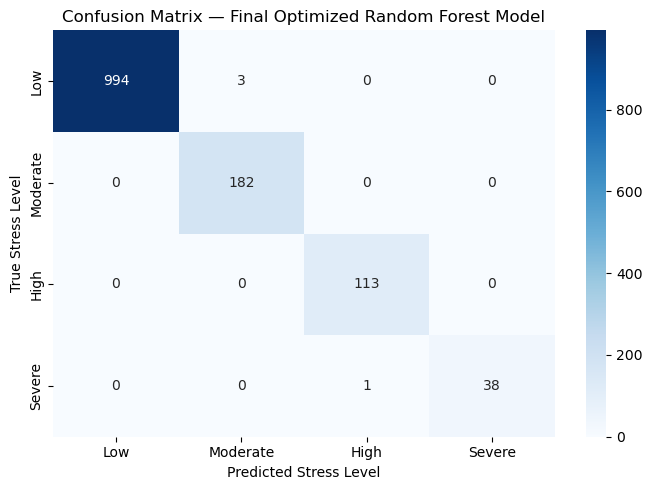

In [26]:
cm_final = confusion_matrix(y_test_class, best_test_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Moderate", "High", "Severe"],
    yticklabels=["Low", "Moderate", "High", "Severe"]
)
plt.title("Confusion Matrix — Final Optimized Random Forest Model")
plt.xlabel("Predicted Stress Level")
plt.ylabel("True Stress Level")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
class_report_text = classification_report(
    y_test_class,
    best_test_preds,
    target_names=["Low", "Moderate", "High", "Severe"],
    digits=4
)
print("Complete Classification Report — Final Optimized Model:")
print(class_report_text)

report_lines = [
    "Best Pipeline: " + best_overall_name,
    "Best CV Macro F1-Score: " + str(round(best_cv_macro, 4)),
    "Best Hyperparameters: " + str(best_hyperparams),
    "Test Accuracy: " + str(round(final_test_acc, 4)),
    "Test Precision (Weighted): " + str(round(final_test_prec, 4)),
    "Test Recall (Weighted): " + str(round(final_test_rec, 4)),
    "Test Weighted F1-Score: " + str(round(final_test_wf1, 4)),
    "Test Macro F1-Score: " + str(round(final_test_mf1, 4)),
    "Test ROC-AUC (Weighted OvR): " + str(round(final_test_auc, 4)),
    "",
    class_report_text
]
with open("classification_report.txt", "w") as report_file:
    for line_text in report_lines:
        report_file.write(line_text + chr(10))

Complete Classification Report — Final Optimized Model:
              precision    recall  f1-score   support

         Low     1.0000    0.9970    0.9985       997
    Moderate     0.9838    1.0000    0.9918       182
        High     0.9912    1.0000    0.9956       113
      Severe     1.0000    0.9744    0.9870        39

    accuracy                         0.9970      1331
   macro avg     0.9938    0.9928    0.9932      1331
weighted avg     0.9970    0.9970    0.9970      1331



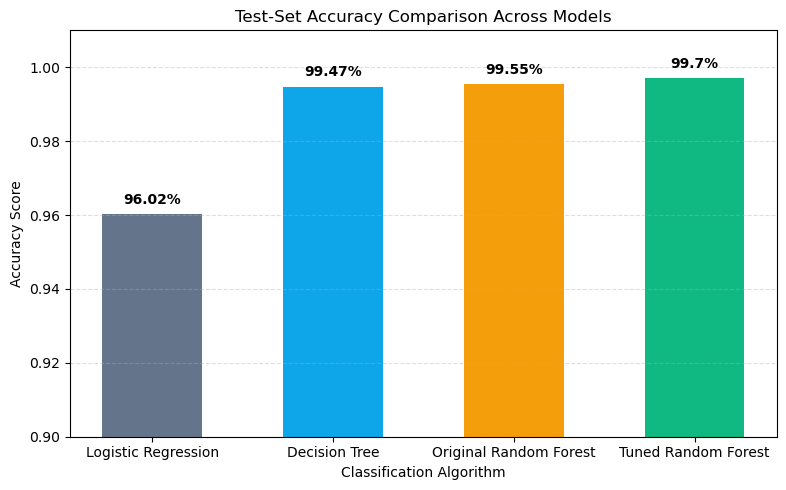

In [28]:
plt.figure(figsize=(8, 5))
acc_colors = ["#64748b", "#0ea5e9", "#f59e0b", "#10b981"]
bars = plt.bar(four_model_comparison_df["Model"], four_model_comparison_df["Accuracy"], color=acc_colors, width=0.55)
plt.ylim(0.90, 1.01)
for bar_item in bars:
    bar_h = bar_item.get_height()
    plt.text(bar_item.get_x() + bar_item.get_width() / 2.0, bar_h + 0.002, str(round(bar_h * 100, 2)) + "%", ha="center", va="bottom", fontweight="bold")
plt.title("Test-Set Accuracy Comparison Across Models")
plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy Score")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

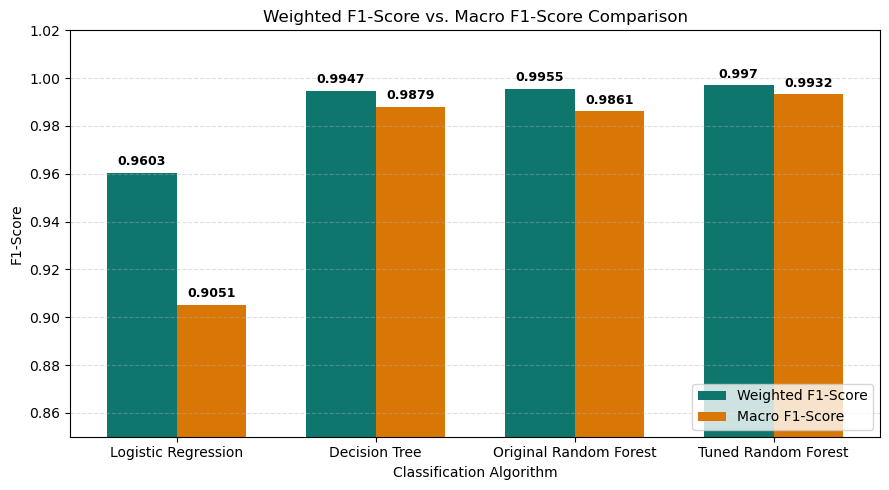

In [29]:
plt.figure(figsize=(9, 5))
x_idx = np.arange(len(four_model_comparison_df))
bar_w = 0.35
b1 = plt.bar(x_idx - bar_w / 2, four_model_comparison_df["Weighted F1"], width=bar_w, label="Weighted F1-Score", color="#0f766e")
b2 = plt.bar(x_idx + bar_w / 2, four_model_comparison_df["Macro F1"], width=bar_w, label="Macro F1-Score", color="#d97706")
plt.xticks(x_idx, four_model_comparison_df["Model"])
plt.ylim(0.85, 1.02)
for b in b1:
    h_val = b.get_height()
    plt.text(b.get_x() + b.get_width() / 2.0, h_val + 0.002, str(round(h_val, 4)), ha="center", va="bottom", fontsize=9, fontweight="bold")
for b in b2:
    h_val = b.get_height()
    plt.text(b.get_x() + b.get_width() / 2.0, h_val + 0.002, str(round(h_val, 4)), ha="center", va="bottom", fontsize=9, fontweight="bold")
plt.title("Weighted F1-Score vs. Macro F1-Score Comparison")
plt.xlabel("Classification Algorithm")
plt.ylabel("F1-Score")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("f1_score_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

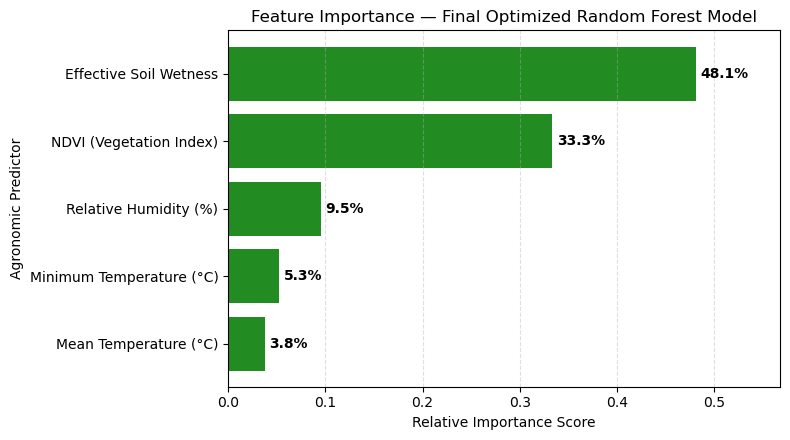

,Feature,Importance
0,Effective Soil Wetness,0.481069
1,NDVI (Vegetation Index),0.333311
2,Relative Humidity (%),0.095330
3,Minimum Temperature (°C),0.052705
4,Mean Temperature (°C),0.037585


In [30]:
readable_feature_names = {
    "temperature": "Mean Temperature (°C)",
    "temp_max": "Maximum Temperature (°C)",
    "temp_min": "Minimum Temperature (°C)",
    "rainfall": "Rainfall (mm/day)",
    "humidity": "Relative Humidity (%)",
    "effective_soil_wetness": "Effective Soil Wetness",
    "solar_radiation": "Solar Radiation (MJ/m²/day)",
    "soil_ph": "Soil pH",
    "soil_organic_carbon": "Soil Organic Carbon (%)",
    "ndvi": "NDVI (Vegetation Index)",
    "et0": "Reference ET0 (mm/day)",
    "etc": "Crop Evapotranspiration ETc (mm/day)",
    "crop_code": "Crop Type",
    "stage_code": "Crop Growth Stage"
}

if hasattr(best_model, "named_steps") and "clf" in best_model.named_steps:
    final_rf_est = best_model.named_steps["clf"]
    if "rfe" in best_model.named_steps:
        active_cols = [col for col, keep in zip(feature_cols, best_model.named_steps["rfe"].support_) if keep]
    else:
        active_cols = feature_cols
    active_imp = final_rf_est.feature_importances_
else:
    active_cols = feature_cols
    active_imp = rf_probe.feature_importances_

opt_imp_df = pd.DataFrame({
    "Feature": [readable_feature_names.get(col, col) for col in active_cols],
    "Importance": active_imp
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

plt.figure(figsize=(8, 4.5))
opt_imp_plot = opt_imp_df.sort_values(by="Importance", ascending=True)
bars_fi = plt.barh(opt_imp_plot["Feature"], opt_imp_plot["Importance"], color="forestgreen")
for b_fi in bars_fi:
    w_fi = b_fi.get_width()
    plt.text(w_fi + 0.005, b_fi.get_y() + b_fi.get_height() / 2.0, str(round(w_fi * 100, 1)) + "%", va="center", fontweight="bold")
plt.xlim(0, opt_imp_df["Importance"].max() * 1.18)
plt.title("Feature Importance — Final Optimized Random Forest Model")
plt.xlabel("Relative Importance Score")
plt.ylabel("Agronomic Predictor")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
opt_imp_df

In [31]:
joblib.dump(scaler, "feature_scaler.pkl")
joblib.dump(best_model, "crop_stress_classifier.pkl")
joblib.dump(model_rf_reg, "irrigation_priority_regressor.pkl")
joblib.dump(model_dt_class, "crop_stress_decision_tree.pkl")
joblib.dump(model_logreg, "crop_stress_logistic_regression.pkl")
joblib.dump(model_dt_reg, "irrigation_decision_tree.pkl")
joblib.dump(model_linreg, "irrigation_linear_regression.pkl")

loaded_pipeline = joblib.load("crop_stress_classifier.pkl")
sample_reload_preds = loaded_pipeline.predict(X_test.iloc[:5])
print("Saved & reloaded crop_stress_classifier.pkl predictions:", sample_reload_preds.tolist())

Saved & reloaded crop_stress_classifier.pkl predictions: [0, 2, 0, 0, 0]


In [32]:
df_districts = df[df["granularity"] == "district_baseline"].copy().reset_index(drop=True)
df_districts.head()

,record_id,granularity,state,district,zone,latitude,longitude,date,year,month,...,shc_macro_soil_ph_acidic_share_2024_25,shc_macro_soil_ph_neutral_share_2024_25,shc_macro_soil_ph_alkaline_share_2024_25,shc_macro_electrical_conductivity_saline_share_2024_25,shc_micro_zinc_deficient_share_2024_25,shc_micro_iron_deficient_share_2024_25,shc_micro_boron_deficient_share_2024_25,nitrogen_status,soil_ph_character,soil_health_index
0,KMD_DIST_0001,district_baseline,Andaman and Nicobar,North and Middle Andaman,South,12.8422,92.8700,NaN,2025,10,...,15.0,70.0,15.0,5.0,25.0,15.0,10.0,Medium,Neutral,68.5
1,KMD_DIST_0002,district_baseline,Andaman and Nicobar,South Andaman,South,20.0000,78.0000,NaN,2025,10,...,15.0,70.0,15.0,5.0,25.0,15.0,10.0,Medium,Neutral,68.5
2,KMD_DIST_0003,district_baseline,Andaman and Nicobar,Nicobars,South,7.5117,93.5955,NaN,2025,10,...,15.0,70.0,15.0,5.0,25.0,15.0,10.0,Medium,Neutral,68.5
3,KMD_DIST_0004,district_baseline,Andhra Pradesh,Srikakulam,South,18.5848,84.1166,NaN,2025,10,...,15.0,70.0,15.0,5.0,25.0,15.0,10.0,Medium,Neutral,68.5
4,KMD_DIST_0005,district_baseline,Andhra Pradesh,Vizianagaram,South,18.2796,83.4137,NaN,2025,10,...,15.0,70.0,15.0,5.0,25.0,15.0,10.0,Medium,Neutral,68.5


In [33]:
X_732 = df_districts[feature_cols].copy()
X_732_scaled = pd.DataFrame(scaler.transform(X_732), columns=feature_cols)

In [34]:
df_districts["Irrigation_Priority_Index"] = np.round(np.clip(model_rf_reg.predict(X_732_scaled), 0.0, 100.0), 1)
df_districts["Stress_Level_Code"] = best_model.predict(X_732)
stress_label_dict = {0: "Low", 1: "Moderate", 2: "High", 3: "Severe"}
df_districts["Crop_Water_Stress"] = df_districts["Stress_Level_Code"].map(stress_label_dict)

df_districts["Priority_Category"] = np.where(
    df_districts["Irrigation_Priority_Index"] >= 50.0, "High Priority",
    np.where(df_districts["Irrigation_Priority_Index"] >= 35.0, "Medium Priority", "Low Priority")
)

df_districts["Recommended_Water_Depth"] = np.where(
    df_districts["Irrigation_Priority_Index"] >= 50.0, "40–50 mm",
    np.where(df_districts["Irrigation_Priority_Index"] >= 35.0, "25–35 mm", "Routine / Nil")
)

df_ranked_732 = df_districts.sort_values(by="Irrigation_Priority_Index", ascending=False).reset_index(drop=True)
df_ranked_732["Rank"] = range(1, len(df_ranked_732) + 1)
df_ranked_732[["Rank", "district", "state", "Irrigation_Priority_Index", "Priority_Category", "Recommended_Water_Depth"]].head(10)

,Rank,district,state,Irrigation_Priority_Index,Priority_Category,Recommended_Water_Depth
0,1,Bikaner,Rajasthan,61.9,High Priority,40–50 mm
1,2,Jaisalmer,Rajasthan,55.2,High Priority,40–50 mm
2,3,Barmer,Rajasthan,53.1,High Priority,40–50 mm
3,4,Ganganagar,Rajasthan,48.3,Medium Priority,25–35 mm
4,5,Nagaur,Rajasthan,47.9,Medium Priority,25–35 mm
5,6,Hanumangarh,Rajasthan,47.9,Medium Priority,25–35 mm
6,7,Churu,Rajasthan,47.4,Medium Priority,25–35 mm
7,8,Namakkal,Tamil Nadu,47.2,Medium Priority,25–35 mm
8,9,Kutch,Gujarat,46.8,Medium Priority,25–35 mm
9,10,Dhule,Maharashtra,44.6,Medium Priority,25–35 mm


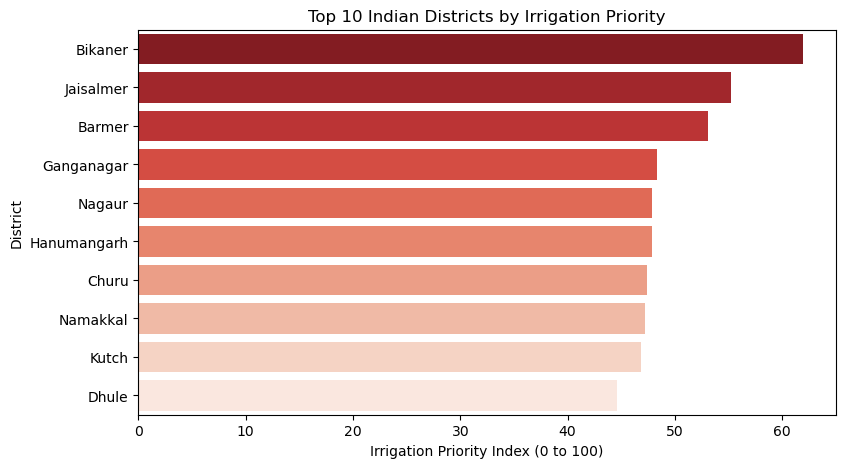

In [35]:
plt.figure(figsize=(9, 5))
top10_districts = df_ranked_732.head(10)
sns.barplot(
    data=top10_districts,
    x="Irrigation_Priority_Index",
    y="district",
    hue="district",
    palette="Reds_r",
    legend=False
)
plt.title("Top 10 Indian Districts by Irrigation Priority")
plt.xlabel("Irrigation Priority Index (0 to 100)")
plt.ylabel("District")
plt.show()

In [36]:
priority_summary = df_ranked_732["Priority_Category"].value_counts()
priority_summary

Priority_Category
Low Priority       608
Medium Priority    121
High Priority        3
Name: count, dtype: int64

In [37]:
clustering_features = [
    "temperature", "rainfall", "humidity", "effective_soil_wetness",
    "solar_radiation", "soil_ph", "soil_organic_carbon", "ndvi", "et0", "etc"
]
scaler_clustering = StandardScaler()
X_cluster_scaled = scaler_clustering.fit_transform(df_ranked_732[clustering_features])

kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=10)
df_ranked_732["Cluster_ID"] = kmeans_model.fit_predict(X_cluster_scaled)

zone_names = {
    0: "Zone 0: Cool Mountain & High-Altitude",
    1: "Zone 1: Humid Coastal & Floodplain",
    2: "Zone 2: Semi-Arid & Deficit Core",
    3: "Zone 3: Wet Tropical & Heavy Rain"
}
df_ranked_732["Cluster_Zone"] = df_ranked_732["Cluster_ID"].map(zone_names)
df_ranked_732["Cluster_Zone"].value_counts()

Cluster_Zone
Zone 0: Cool Mountain & High-Altitude    392
Zone 1: Humid Coastal & Floodplain       165
Zone 3: Wet Tropical & Heavy Rain        131
Zone 2: Semi-Arid & Deficit Core          44
Name: count, dtype: int64

In [38]:
pca_model = PCA(n_components=2, random_state=42)
pca_coordinates = pca_model.fit_transform(X_cluster_scaled)
df_ranked_732["PCA_X"] = np.round(pca_coordinates[:, 0], 2)
df_ranked_732["PCA_Y"] = np.round(pca_coordinates[:, 1], 2)
pca_model.explained_variance_ratio_

array([0.47676291, 0.34083872])

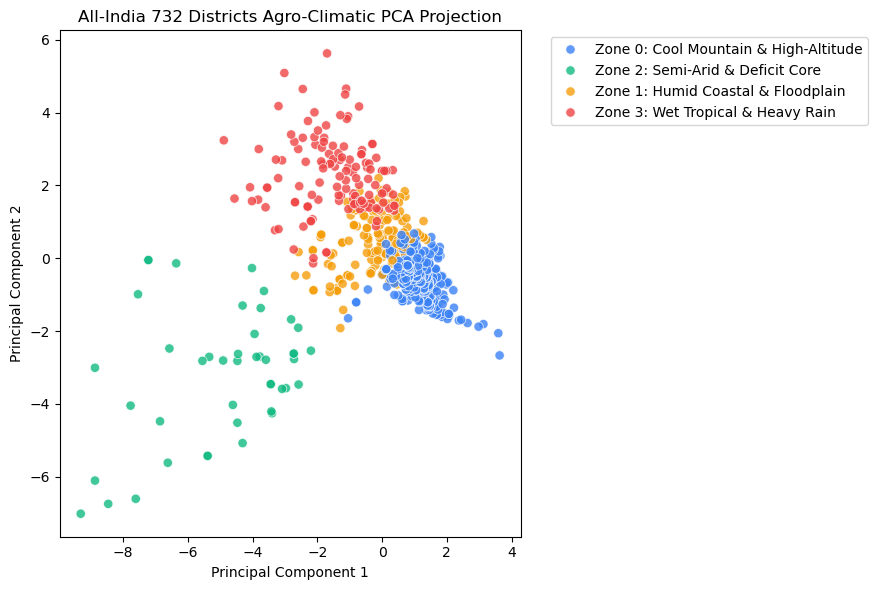

In [39]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_ranked_732,
    x="PCA_X",
    y="PCA_Y",
    hue="Cluster_Zone",
    palette=["#3b82f6", "#10b981", "#f59e0b", "#ef4444"],
    alpha=0.8,
    s=45
)
plt.title("All-India 732 Districts Agro-Climatic PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [40]:
cluster_characterization = df_ranked_732.groupby("Cluster_Zone")[
    ["temperature", "rainfall", "humidity", "effective_soil_wetness", "Irrigation_Priority_Index"]
].mean().round(2)
cluster_characterization

,temperature,rainfall,humidity,effective_soil_wetness,Irrigation_Priority_Index
Cluster_Zone,,,,,
Zone 0: Cool Mountain & High-Altitude,25.38,3.56,59.53,0.36,33.77
Zone 1: Humid Coastal & Floodplain,24.18,6.03,72.61,0.44,26.08
Zone 2: Semi-Arid & Deficit Core,8.56,5.03,70.90,0.43,27.84
Zone 3: Wet Tropical & Heavy Rain,24.06,7.09,73.32,0.65,10.48


In [41]:
df_ranked_732.to_csv("all_india_732_districts_priority_and_clusters.csv", index=False)
df_ranked_732.shape

(732, 82)